# Use Case 2: Exploring and Visualising the Crime Data

Here I look for trends and patterns using Pandas, NumPy, Matplotlib and Seaborn.

Input: `output/chicago_crime_clean.pkl` from notebook 01.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from IPython.display import display

import crime_utils as cu

cu.set_style()
df = pd.read_pickle(cu.CLEAN_CRIME_FILE)
print(f"{len(df):,} crimes | {df['date'].min():%d %b %Y} to {df['date'].max():%d %b %Y}")

498 crimes | 01 Jan 2012 to 04 May 2016


## 1. Crimes per year

`groupby('year').size()` counts the rows for each year.

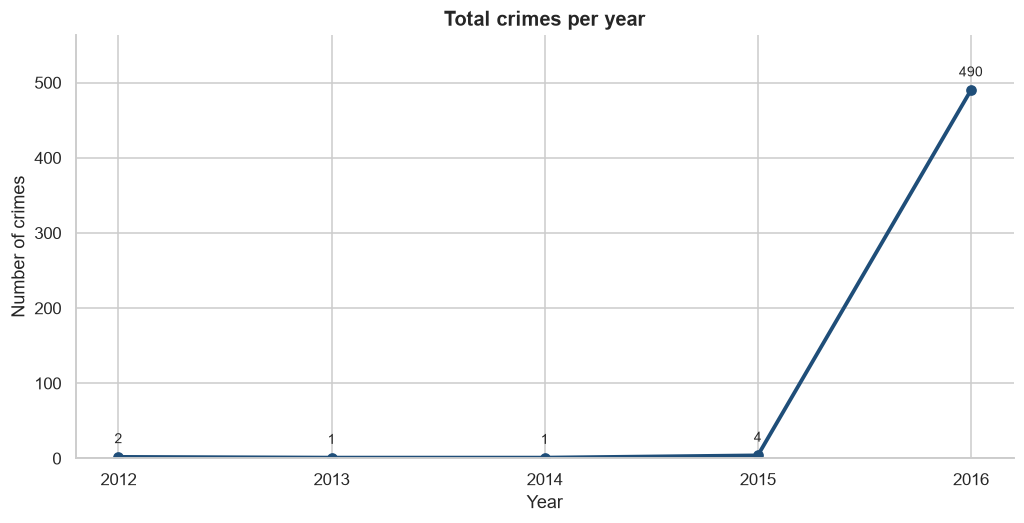

In [2]:
yearly = df.groupby("year").size().rename("crimes")

fig, ax = plt.subplots()
ax.plot(yearly.index, yearly.values, marker="o", linewidth=2.5, color="#1f4e79")
for x, y in yearly.items():
    ax.annotate(f"{y:,}", (x, y), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=9)
ax.set(title="Total crimes per year", xlabel="Year", ylabel="Number of crimes")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.set_xticks(yearly.index)
ax.set_ylim(0, yearly.max() * 1.15)
cu.save_fig(fig, "uc2_01_crimes_per_year")
plt.show()

### Is crime going up or down?
Reading the chart, with the numbers behind it.

In [3]:
display(yearly.to_frame().T)
months_covered = df.groupby("year")["month"].nunique()
top_year, top_share = yearly.idxmax(), yearly.max() / yearly.sum() * 100
others = yearly.drop(top_year)
print(f"The line looks like it rises, but {top_year} holds {top_share:.1f}% of the rows, "
      f"{'no year is complete' if (months_covered < 12).all() else 'not every year is complete'} "
      f"and the earlier years only hold {others.min()}–{others.max()} late-reported crimes each, "
      "so a rising or falling trend can't be read from this extract.")

year,2012,2013,2014,2015,2016
crimes,2,1,1,4,490


The line looks like it rises, but 2016 holds 98.4% of the rows, no year is complete and the earlier years only hold 1–4 late-reported crimes each, so a rising or falling trend can't be read from this extract.


## 2. Crimes by category (`primary_type`)
`value_counts()` gives the counts sorted from highest to lowest, and `normalize=True` turns them into proportions.

In [4]:
cat = pd.DataFrame({
    "count": df["primary_type"].value_counts(),
    "percent": df["primary_type"].value_counts(normalize=True).mul(100).round(2),
})
top10 = cat.head(10)
display(top10)

,count,percent
primary_type,,
THEFT,105,21.08
BATTERY,85,17.07
CRIMINAL DAMAGE,49,9.84
OTHER OFFENSE,39,7.83
DECEPTIVE PRACTICE,38,7.63
ASSAULT,35,7.03
NARCOTICS,32,6.43
ROBBERY,30,6.02
CRIMINAL TRESPASS,17,3.41


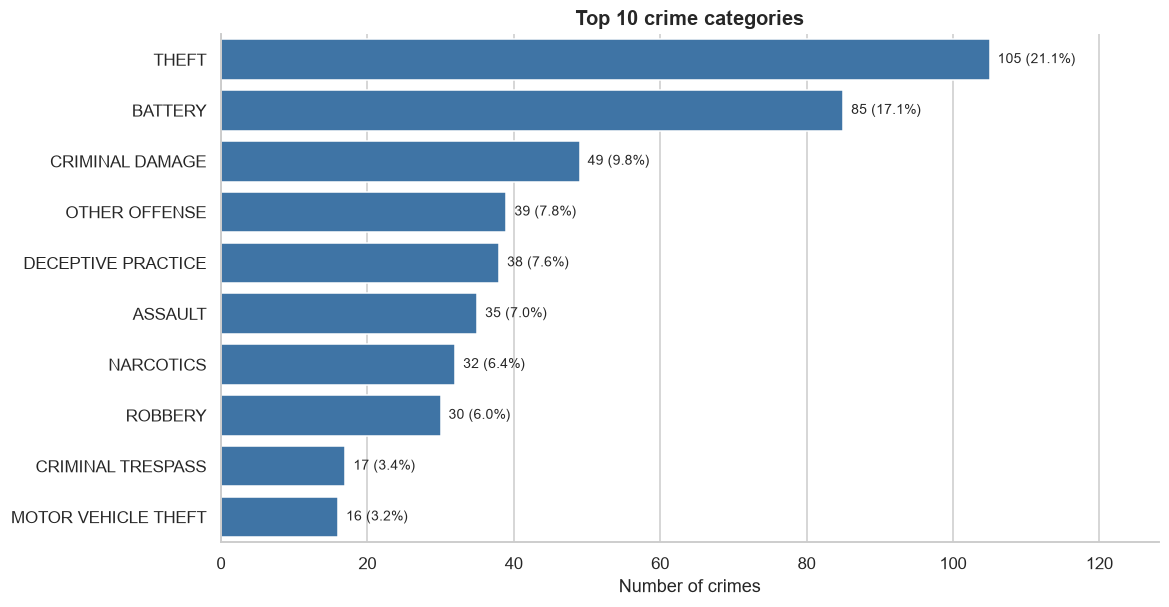

In [5]:
fig, ax = plt.subplots(figsize=(11, 6))
sns.barplot(x=top10["count"], y=top10.index, ax=ax, color="#2e75b6")
for i, (c, p) in enumerate(zip(top10["count"], top10["percent"])):
    ax.text(c, i, f"  {c:,} ({p:.1f}%)", va="center", fontsize=9)
ax.set(title="Top 10 crime categories", xlabel="Number of crimes", ylabel="")
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.set_xlim(0, top10["count"].max() * 1.22)
cu.save_fig(fig, "uc2_02_top10_categories")
plt.show()

## 3. Arrests
`arrest` is a boolean column. The mean of a boolean column is the share of True values, so `mean() * 100` is the arrest rate.

In [6]:
arrest_rate = df["arrest"].mean() * 100
print(f"Overall arrest rate: {arrest_rate:.2f}%  "
      f"({df['arrest'].sum():,} arrests out of {len(df):,} crimes)")

Overall arrest rate: 24.90%  (124 arrests out of 498 crimes)


## 4. Heatmap of crimes by month and day of week
`pivot_table` turns the data into a 12 x 7 grid (months by weekdays). I reindex the columns so the days run Monday to Sunday instead of alphabetically.

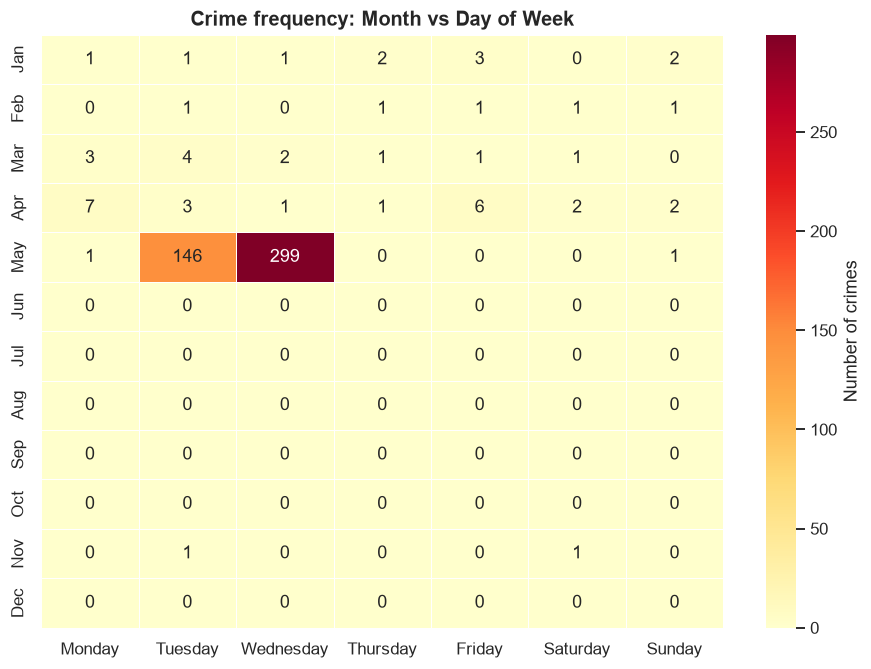

Busiest cell: May / Wednesday (299 crimes)
Busiest weekday overall: Wednesday | quietest: Thursday
Note: one cell holds 60% of all crimes — the heatmap mostly shows *when the extract was taken* (Tue 3 / Wed 4 May 2016), not a seasonal or weekly crime pattern.


In [7]:
pivot = (df.pivot_table(index="month", columns="day_of_week", values="case_number",
                        aggfunc="count", fill_value=0)
           .reindex(index=range(1, 13), columns=cu.DAY_ORDER, fill_value=0)   # all 12 x 7 cells
           .astype(int))
pivot.index = cu.MONTH_NAMES

fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(pivot, annot=True, fmt=",d", cmap="YlOrRd", linewidths=.5,
            cbar_kws={"label": "Number of crimes"}, ax=ax)
ax.set(title="Crime frequency: Month vs Day of Week", xlabel="", ylabel="")
cu.save_fig(fig, "uc2_04_heatmap_month_day")
plt.show()

busiest = pivot.stack().idxmax()
print(f"Busiest cell: {busiest[0]} / {busiest[1]} ({pivot.stack().max():,} crimes)")
print(f"Busiest weekday overall: {pivot.sum().idxmax()} | quietest: {pivot.sum().idxmin()}")
busy_share = pivot.stack().max() / pivot.values.sum() * 100
if busy_share > 30:
    print(f"Note: one cell holds {busy_share:.0f}% of all crimes — the heatmap mostly shows *when the extract "
          "was taken* (Tue 3 / Wed 4 May 2016), not a seasonal or weekly crime pattern.")

## 5. Top community areas
`community_code` is only a number, so I join the community lookup to get the names. Crimes without a known community are left out of this ranking.

In [8]:
community = pd.read_pickle(cu.OUTPUT_DIR / "community_lookup.pkl")
names = community.set_index("community_code")["community_name"]

top_areas = (df["community_code"].dropna().astype(int).value_counts().head(10)
               .rename_axis("community_code").reset_index(name="crimes"))
top_areas["community_name"] = top_areas["community_code"].map(names).str.title()
top_areas["percent"] = (top_areas["crimes"] / df["community_code"].notna().sum() * 100).round(2)
display(top_areas)

,community_code,crimes,community_name,percent
0,25,34,Austin,6.83
1,8,20,Near North Side,4.02
2,23,20,Humboldt Park,4.02
3,43,16,South Shore,3.21
4,68,16,Englewood,3.21
5,30,16,South Lawndale,3.21
6,32,15,Loop,3.01
7,71,14,Auburn Gresham,2.81
8,6,14,Lake View,2.81
9,49,14,Roseland,2.81


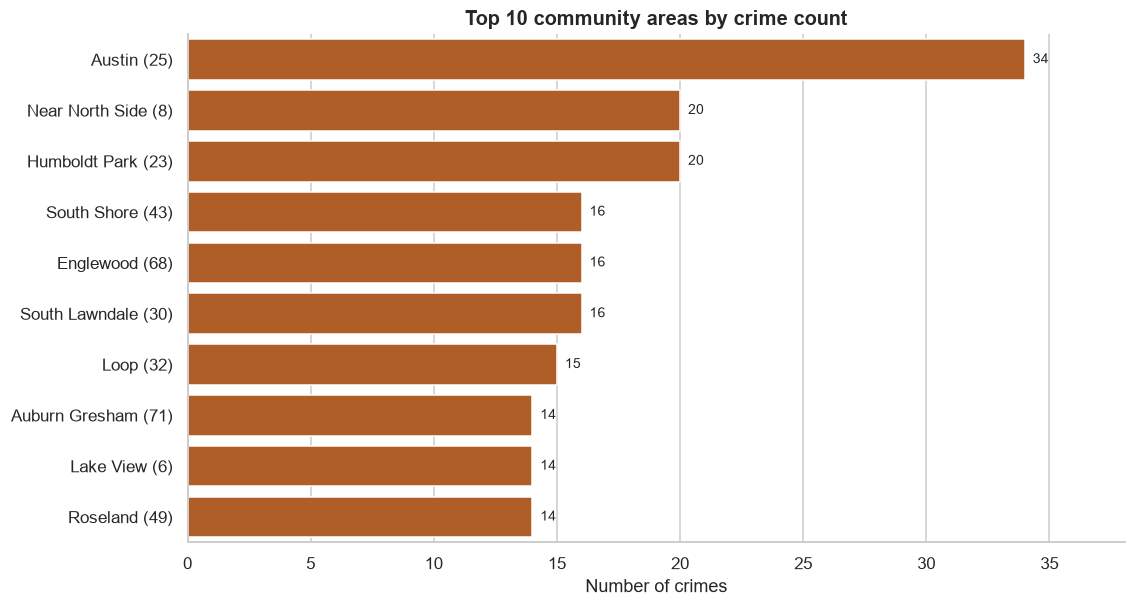

In [9]:
fig, ax = plt.subplots(figsize=(11, 6))
labels = top_areas["community_name"] + " (" + top_areas["community_code"].astype(str) + ")"
sns.barplot(x=top_areas["crimes"], y=labels, ax=ax, color="#c55a11")
for i, c in enumerate(top_areas["crimes"]):
    ax.text(c, i, f"  {c:,}", va="center", fontsize=9)
ax.set(title="Top 10 community areas by crime count", xlabel="Number of crimes", ylabel="")
ax.set_xlim(0, top_areas["crimes"].max() * 1.12)
cu.save_fig(fig, "uc2_05_top10_communities")
plt.show()

## Questions
### Q1. Which crime category is the most common?

In [10]:
print(f"Most frequent: {cat.index[0]} — {cat['count'].iloc[0]:,} crimes ({cat['percent'].iloc[0]:.2f}%)")
print(f"Runner-up:     {cat.index[1]} — {cat['count'].iloc[1]:,} crimes ({cat['percent'].iloc[1]:.2f}%)")

Most frequent: THEFT — 105 crimes (21.08%)
Runner-up:     BATTERY — 85 crimes (17.07%)


### Q2. Is the arrest rate consistent from year to year?
The rate for each year, with the number of crimes behind it.

In [11]:
yr = df.groupby("year")["arrest"].agg(crimes="size", arrests="sum", rate="mean")
yr["rate"] = (yr["rate"] * 100).round(2)
display(yr.T)
small = yr[yr["crimes"] < 30]
print(f"Only {', '.join(map(str, yr.index[yr['crimes'] >= 30]))} has enough crimes for a stable rate; "
      f"{small.index.min()}–{small.index.max()} have {small['crimes'].min()}–{small['crimes'].max()} each, "
      "so consistency across years can't be judged.")

year,2012,2013,2014,2015,2016
crimes,2.0,1.0,1.0,4.0,490.00
arrests,2.0,1.0,0.0,2.0,119.00
rate,100.0,100.0,0.0,50.0,24.29


Only 2016 has enough crimes for a stable rate; 2012–2015 have 1–4 each, so consistency across years can't be judged.


### Q3. Which month has the most crime?

In [12]:
monthly = df.groupby("month").size().reindex(range(1, 13), fill_value=0)
monthly.index = cu.MONTH_NAMES
display(monthly.rename("crimes").to_frame().T)
share = monthly.max() / monthly.sum() * 100
print(f"Highest: {monthly.idxmax()} with {monthly.max():,} crimes ({share:.1f}% of all crimes). "
      "That reflects when the extract was taken (early May 2016), not seasonality.")

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
crimes,10,5,12,22,447,0,0,0,0,0,2,0


Highest: May with 447 crimes (89.8% of all crimes). That reflects when the extract was taken (early May 2016), not seasonality.
